# Classification with Logistic Regression and SVM

We will be working with the [Titanic Data Set from Kaggle](https://www.kaggle.com/c/titanic). We'll be trying to predict a classification: survival or deceased.

 - **Variable Name -  Variable Description**
 - PassengerID - Passenger ID          
 - Survived - Survival (0 = No; 1 = Yes)
 - Pclass - Passenger Class (1 = 1st; 2 = 2nd; 3 = 3rd)
 - Name	- Name
 - Sex - Sex
 - Age - Age in years
 - SibSp - Number of Siblings/Spouses Aboard
 - Parch - Number of Parents/Children Aboard
 - Ticket - Ticket Number
 - Fare - Passenger Fare
 - Cabin - Cabin number
 - Embarked - Port of Embarkation (C = Cherbourg; Q = Queenstown; S = Southampton)

### a. Import Libraries

Import all necessary libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import roc_curve, auc,precision_recall_curve

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.calibration import CalibrationDisplay

import numpy as np

Our target variable will be **survived**.  Use the rest of the fields mentioned above to predict whether a passenger survived the Titanic shipwreck.

### b.	Data Loading / Preprocessing
#### i.	Loading
1. Load the data <df_train.csv> and <df_test.csv> as a pandas dataframe using the `pandas.read_csv` function. The ‘df_test.csv’ has been preprocessed (i.e., null values have been dropped, certain columns etc. have been dropped) and should not be changed apart from splitting the dataframe into X_test and y_test.  The ‘df_train’ data has NOT been preprocessed and you will need to preprocess and prepare the ‘df_train’ dataframe. Note: Neither df_train nor df_test have been scaled. The next few steps will enumerate data preprocessing, scaling requirements we need to perform.

In [2]:
import pandas as pd

df_train = pd.read_csv("df_train.csv")
df_test = pd.read_csv("df_test.csv")


2. The resulting dataframe (i.e., df_train) should have the shape (712,12) indicating that there are 712 instances and 12 columns.

In [9]:
import pandas as pd

# Loading the data
df_train = pd.read_csv('df_train.csv')


df_train = df_train[df_train['Survived'].notna()]

df_train = df_train.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
df_train['Age'] = df_train['Age'].fillna(df_train['Age'].median())
df_train['Embarked'] = df_train['Embarked'].fillna(df_train['Embarked'].mode()[0])

df_train['Sex'] = df_train['Sex'].map({'male': 0, 'female': 1})
df_train = pd.get_dummies(df_train, columns=['Embarked'], drop_first=True)

print(df_train.shape)



(712, 9)


3. In df_train dataframe, currently you have 12 columns which are the following – PassengerID, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked and the Survived column (target variable).

4. Use the `pandas.isnull().sum()` function to check if there are any missing values in the df_train dataframe. Report which columns have missing (i.e., null) values and provide the number of the null values in the columns.

In [11]:
# Load the training data
df_train = pd.read_csv('df_train.csv')

missing_values = df_train.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values)

Age         138
Cabin       541
Embarked      2
dtype: int64


5. Use the `pandas.DataFrame.drop()` function to drop the ‘Cabin’, ‘PassengerID’, ‘Name’ and ‘Ticket’ columns.

In [12]:
# Drop specified columns
df_train = df_train.drop(columns=['Cabin', 'PassengerId', 'Name', 'Ticket'])

# Confirming the new shape and remaining columns
print(df_train.shape)
print(df_train.columns)


(712, 8)
Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked',
       'Survived'],
      dtype='object')


6. Use the `pandas.DataFrame.fillna()` function to replace the NA values in the ‘Age’ column with the mean value of the ‘Age’ column. Note: This process is called **imputation** (i.e., filling null values with a pre-specified value) and we are employing one strategy called mean imputation, but other strategies can also be employed in general.  
Use the `dropna()` function to drop any remaining **rows** that consist of NA values.

In [13]:
df_train['Age'] = df_train['Age'].fillna(df_train['Age'].mean())
df_train = df_train.dropna()
print(df_train.isnull().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
Survived    0
dtype: int64


7. Your task is to use the feature columns to predict the target column. This can be cast as a classification problem.  
8. Create a pandas dataframe X_train of features (by dropping the ‘Survival’ column from the df_train dataframe). Create a pandas Series object of targets y_train (by only considering the ‘Survival’ column from the df_train dataframe). Moving forward, we will be working with X_train and y_train. At this point, also split the df_test into X_test and y_test by dropping the ‘Survival’ column and storing the features into X_test. Store the ‘Survival’ column in y_test.

In [14]:
# Features (all columns except 'Survived')
X_train = df_train.drop(columns='Survived')

# Target
y_train = df_train['Survived']

X_test = df_test.drop(columns='Survived')
y_test = df_test['Survived']

#### ii. Data Visualization

1. Employ a scatter plot using `matplotlib.pyplot.scatter` between the age of the passengers and the price of their fare. Label the x-axis and the y-axis and also give the plot a title.

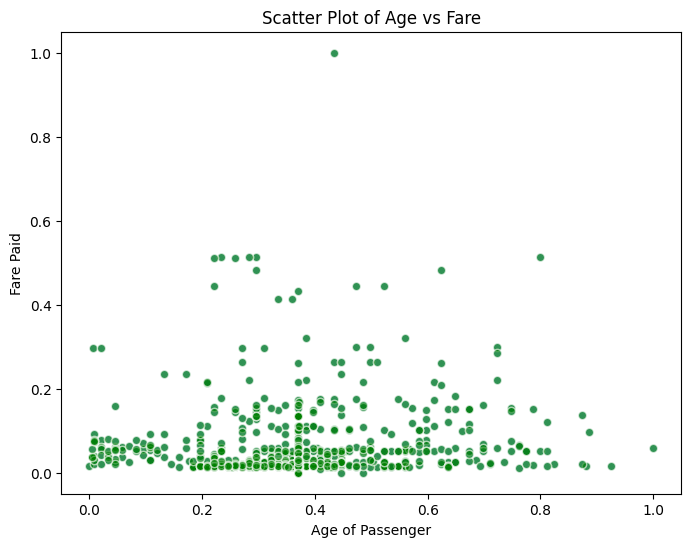

In [32]:
import matplotlib.pyplot as plt

# Scatter plot: Age vs Fare
plt.figure(figsize=(8, 6))
plt.scatter(X_train['Age'], X_train['Fare'], alpha=0.6, edgecolors='w')

# Labeling
plt.xlabel('Age of Passenger')
plt.ylabel('Fare Paid')
plt.title('Scatter Plot of Age vs Fare')

# Show the plot

plt.scatter(
    X_train['Age'],
    X_train['Fare'],
    c='green',
    alpha=0.6,
    edgecolors='w'
)



2. Use the df_train dataframe. Using matplotlib visualize the number of males and females that survived and their respective passenger classes on two separate bar chart plots using `matplotlib.pyplot.bar` (Passenger Class column)

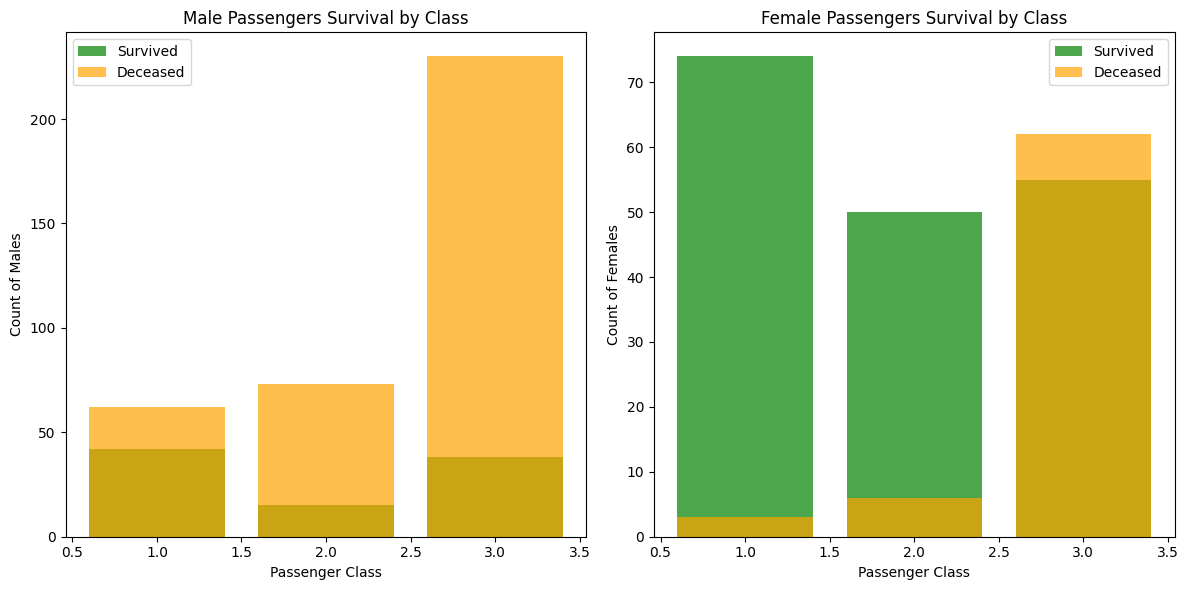

In [33]:
import matplotlib.pyplot as plt

# Filter data for males and females
male_data = df_train[df_train['Sex'] == 'male']
female_data = df_train[df_train['Sex'] == 'female']

# Group by Pclass and Survived, then count
male_survival = male_data.groupby(['Pclass', 'Survived']).size().unstack(fill_value=0)
female_survival = female_data.groupby(['Pclass', 'Survived']).size().unstack(fill_value=0)

# Plot for males
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.bar(
    male_survival.index,
    male_survival[1],
    label='Survived',
    alpha=0.7,
    color='green'
)
plt.bar(
    male_survival.index,
    male_survival[0],
    label='Deceased',
    alpha=0.7,
    color='orange'
)

plt.xlabel('Passenger Class')
plt.ylabel('Count of Males')
plt.title('Male Passengers Survival by Class')
plt.legend()

# Plot for females
plt.subplot(1, 2, 2)
plt.bar(
    female_survival.index,
    female_survival[1],
    label='Survived',
    alpha=0.7,
    color='green'
)
plt.bar(
    female_survival.index,
    female_survival[0],
    label='Deceased',
    alpha=0.7,
    color='orange'
)

plt.xlabel('Passenger Class')
plt.ylabel('Count of Females')
plt.title('Female Passengers Survival by Class')
plt.legend()

# Show the plots
plt.tight_layout()
plt.show()


3. Using the Target variable (Survived) in y_train plot a bar chart showing the distribution of the ‘Survived’ column.

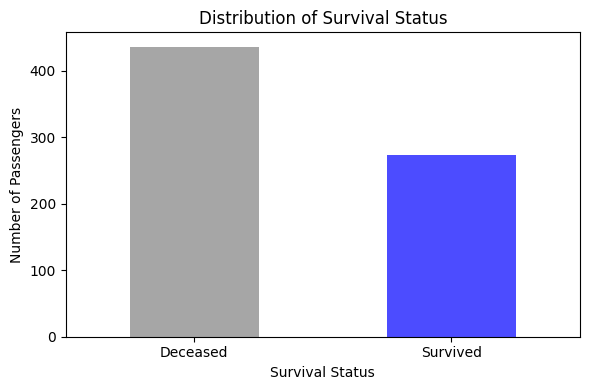

In [34]:
import matplotlib.pyplot as plt

# Plotting the distribution of the 'Survived' column
plt.figure(figsize=(6, 4))
y_train.value_counts().plot(
    kind='bar',
    color=['gray', 'blue'],
    alpha=0.7
)

# Labeling the chart
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')
plt.title('Distribution of Survival Status')
plt.xticks([0, 1], ['Deceased', 'Survived'], rotation=0)

plt.tight_layout()
plt.show()


4. So far you should have successfully been able to load, preprocess and visualize your data. Use the `pd.get_dummies()` function to convert categorical data into dummy variables (‘Sex’ and ‘Embarked’). Make sure to pass `drop_first=True` to the `get_dummies()` function. (Perform this only on X_train and store the result back into X_train).

In [18]:
# Convert categorical columns 'Sex' and 'Embarked' into dummy variables
X_train = pd.get_dummies(X_train, columns=['Sex', 'Embarked'], drop_first=True)

# Display the updated X_train shape and columns
print(X_train.shape)
print(X_train.columns)


(710, 8)
Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q',
       'Embarked_S'],
      dtype='object')


#### iii. Data Scaling

1. Use MinMaxScaler to scale only the **continuous attributes** of X_train. Apply the `fit_transform()` function of the scaler to obtain the scaled data and store it back in X_train.

In [19]:
from sklearn.preprocessing import MinMaxScaler

# List of continuous columns
continuous_columns = ['Age', 'Fare', 'SibSp', 'Parch']

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Apply scaling to the continuous columns only
X_train[continuous_columns] = scaler.fit_transform(X_train[continuous_columns])

# Display the updated X_train
print(X_train.head())


   Pclass       Age  SibSp     Parch      Fare  Sex_male  Embarked_Q  \
0       1  0.369337  0.000  0.000000  0.059532      True       False   
1       3  0.334004  0.000  0.333333  0.021731     False       False   
2       2  0.369337  0.000  0.000000  0.000000      True       False   
3       3  0.107816  0.500  0.333333  0.061045     False       False   
4       1  0.597889  0.125  0.000000  0.077294     False       False   

   Embarked_S  
0        True  
1        True  
2        True  
3        True  
4       False  


2. Scale the X_test using the scaler you have just fit, this time using the `transform()` function. Note: Store the scaled values back into X_test. At the end of this step, you must have X_train, X_test, all scaled according to the MinMaxScaler.

In [20]:
# Apply the same scaler to X_test (using transform to use the same scale as X_train)
X_test[continuous_columns] = scaler.transform(X_test[continuous_columns])

# Display the scaled X_test
print(X_test.head())


   Pclass       Age  SibSp     Parch      Fare  Sex_male  Embarked_Q  \
0       2  0.623021    0.0  0.166667  0.050749         0           0   
1       1  0.547625    0.0  0.000000  0.054107         0           0   
2       3  0.362113    0.0  0.000000  0.015379         0           1   
3       3  0.057552    0.0  0.000000  0.024350         0           0   
4       2  0.258608    0.0  0.000000  0.143462         1           0   

   Embarked_S  
0           1  
1           0  
2           0  
3           1  
4           1  


### c. Modelling

#### i. Modelling (Model Instantiation / Training) using Logistic Regression classifier

1. Employ the Logistic Regression classifier from sklearn and instantiate the model. Label this model as ‘model_lr’  

In [21]:
from sklearn.linear_model import LogisticRegression

# Instantiate the Logistic Regression model
model_lr = LogisticRegression()


2. Once instantiated, `fit()` the model using the scaled X_train, y_train data.

In [22]:
# Fit the model on the scaled X_train and y_train
model_lr.fit(X_train, y_train)


LogisticRegression()

3. Employ the `predict()` function to obtain predictions on X_test and store this in a variable labeled as ‘y_pred_lr’.

In [23]:
# Use the trained model to predict on X_test
y_pred_lr = model_lr.predict(X_test)


4. Employ the `accuracy_score` function by using the ‘y_pred_lr’ and ‘y_test’ variables as the functions parameters and print the accuracy of the Logistic Regression model.

In [24]:
from sklearn.metrics import accuracy_score

# Calculate accuracy of the model
accuracy = accuracy_score(y_test, y_pred_lr)

# Print the accuracy
print(f'Accuracy of Logistic Regression model: {accuracy:.4f}')


Accuracy of Logistic Regression model: 0.8827


#### ii. Modelling Logistic Regression Classifier with the addition of noise on the target variable.

In the data repository you should see three noisy datasets – `df_train_noise20`, `df_train_noise40`, and `df_train_noise60`. These datasets have already been preprocessed. In each dataset `df_train_noise<integer>`, the integer indicates the percentage of noise injected into the target variable in that training set. The noise can be considered a result of incorrect class labelling of a particular instance. For example, in `df_train_noise20`, 20% of the instances have an incorrect target label in the training set. Our goal will be to train a set of classification models on such noisy training data and test on a clean test set (i.e., same as what we have been using so far `df_test`).

Load the `df_train_noise<nl>` (nl means noise level and is a place holder for the integer percentage) datasets and split the data into `X_train_<nl>` and `y_train_<nl>` (e.g., if working with `df_train_noise20` we would split the data and store it in variables named `X_train_20`, `y_train_20`). `X_train_<nl>` should store the features and `y_train_<nl>` should store the target variable.

**Repeat the following steps (c. i. 1 – 4) for the 20%, 40%, 60% noise level datasets.**  
Train a new Logistic Regression model on the new training and use the pre-existing `X_test` and `y_test` to evaluate your model. Label this model as `model_lr_noise_<nl>`. Specifically, do the following:
1. Employ a new Logistic Regression classifier from sklearn and instantiate the model. Label this model as `model_lr_noise<nl>`
2. Once instantiated, `fit()` the model using the `X_train_<nl>` and `y_train_<nl>` data.
3. Employ the `predict()` function to obtain predictions on `X_test` and store this in a variable labeled as `y_pred_lr_noise<nl>`.
4. Employ the `accuracy_score` function and print the accuracy of the new Logistic Regression model.

In [25]:
# Load df_train_noise20
df_train_noise20 = pd.read_csv('df_train_noise20.csv')

# Split into features and target variable
X_train_20 = df_train_noise20.drop(columns='Survived')
y_train_20 = df_train_noise20['Survived']

# Instantiate the Logistic Regression model
model_lr_noise_20 = LogisticRegression()

# Fit the model on noisy data
model_lr_noise_20.fit(X_train_20, y_train_20)

# Make predictions on the clean test set
y_pred_lr_noise_20 = model_lr_noise_20.predict(X_test)

# Calculate accuracy
accuracy_20 = accuracy_score(y_test, y_pred_lr_noise_20)

# Print accuracy
print(f'Accuracy of Logistic Regression model with 20% noise: {accuracy_20:.4f}')


Accuracy of Logistic Regression model with 20% noise: 0.7039


In [26]:
# Load df_train_noise40
df_train_noise40 = pd.read_csv('df_train_noise40.csv')

# Split into features and target variable
X_train_40 = df_train_noise40.drop(columns='Survived')
y_train_40 = df_train_noise40['Survived']

# Instantiate the Logistic Regression model
model_lr_noise_40 = LogisticRegression()

# Fit the model on noisy data
model_lr_noise_40.fit(X_train_40, y_train_40)

# Make predictions on the clean test set
y_pred_lr_noise_40 = model_lr_noise_40.predict(X_test)

# Calculate accuracy
accuracy_40 = accuracy_score(y_test, y_pred_lr_noise_40)

# Print accuracy
print(f'Accuracy of Logistic Regression model with 40% noise: {accuracy_40:.4f}')


Accuracy of Logistic Regression model with 40% noise: 0.6313


In [27]:
# Load df_train_noise60
df_train_noise60 = pd.read_csv('df_train_noise60.csv')

# Split into features and target variable
X_train_60 = df_train_noise60.drop(columns='Survived')
y_train_60 = df_train_noise60['Survived']

# Instantiate the Logistic Regression model
model_lr_noise_60 = LogisticRegression()

# Fit the model on noisy data
model_lr_noise_60.fit(X_train_60, y_train_60)

# Make predictions on the clean test set
y_pred_lr_noise_60 = model_lr_noise_60.predict(X_test)

# Calculate accuracy
accuracy_60 = accuracy_score(y_test, y_pred_lr_noise_60)

# Print accuracy
print(f'Accuracy of Logistic Regression model with 60% noise: {accuracy_60:.4f}')


Accuracy of Logistic Regression model with 60% noise: 0.4022


### d. Evaluation

#### i. Report F1 Score, Precision, Recall, Accuracy (All on the test set X_test, y_test)

1. Use `classification_report()` function from sklearn.metrics to report the precision, recall, and f1 score for each class for the `model_lr` model, along with a confusion matrix.

In [28]:
from sklearn.metrics import classification_report, confusion_matrix

# Generating classification report for model_lr on the clean test set
print("Classification Report for Logistic Regression (model_lr):")
print(classification_report(y_test, y_pred_lr))

# Generating and print confusion matrix for model_lr
conf_matrix = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix for Logistic Regression (model_lr):")
print(conf_matrix)


Classification Report for Logistic Regression (model_lr):
              precision    recall  f1-score   support

           0       0.90      0.92      0.91       113
           1       0.86      0.82      0.84        66

    accuracy                           0.88       179
   macro avg       0.88      0.87      0.87       179
weighted avg       0.88      0.88      0.88       179

Confusion Matrix for Logistic Regression (model_lr):
[[104   9]
 [ 12  54]]


#### ii. Report the accuracy and classification report for each of the three noisy models (`model_lr_noise<nl>`)

In [29]:
from sklearn.metrics import classification_report, accuracy_score

# For the model_lr_noise_20
y_pred_lr_noise_20 = model_lr_noise_20.predict(X_test)
accuracy_20 = accuracy_score(y_test, y_pred_lr_noise_20)
print(f'Accuracy of Logistic Regression model with 20% noise: {accuracy_20:.4f}')
print("Classification Report for Logistic Regression (model_lr_noise_20):")
print(classification_report(y_test, y_pred_lr_noise_20))

# For the model_lr_noise_40
y_pred_lr_noise_40 = model_lr_noise_40.predict(X_test)
accuracy_40 = accuracy_score(y_test, y_pred_lr_noise_40)
print(f'Accuracy of Logistic Regression model with 40% noise: {accuracy_40:.4f}')
print("Classification Report for Logistic Regression (model_lr_noise_40):")
print(classification_report(y_test, y_pred_lr_noise_40))

# For the model_lr_noise_60
y_pred_lr_noise_60 = model_lr_noise_60.predict(X_test)
accuracy_60 = accuracy_score(y_test, y_pred_lr_noise_60)
print(f'Accuracy of Logistic Regression model with 60% noise: {accuracy_60:.4f}')
print("Classification Report for Logistic Regression (model_lr_noise_60):")
print(classification_report(y_test, y_pred_lr_noise_60))


Accuracy of Logistic Regression model with 20% noise: 0.7039
Classification Report for Logistic Regression (model_lr_noise_20):
              precision    recall  f1-score   support

           0       0.68      1.00      0.81       113
           1       1.00      0.20      0.33        66

    accuracy                           0.70       179
   macro avg       0.84      0.60      0.57       179
weighted avg       0.80      0.70      0.63       179

Accuracy of Logistic Regression model with 40% noise: 0.6313
Classification Report for Logistic Regression (model_lr_noise_40):
              precision    recall  f1-score   support

           0       0.63      1.00      0.77       113
           1       0.00      0.00      0.00        66

    accuracy                           0.63       179
   macro avg       0.32      0.50      0.39       179
weighted avg       0.40      0.63      0.49       179

Accuracy of Logistic Regression model with 60% noise: 0.4022
Classification Report for Log

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### iii. Make a calibration plot for `model_lr`

Use the `CalibrationDisplay` class from sklearn.calibration to make your plot.

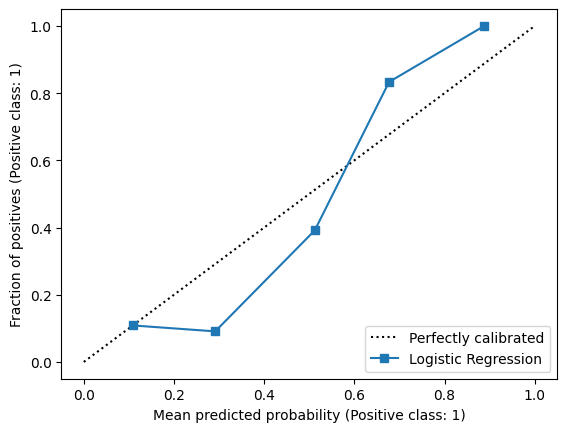

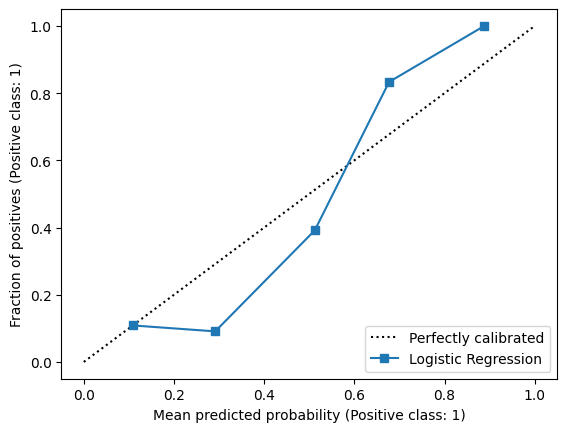

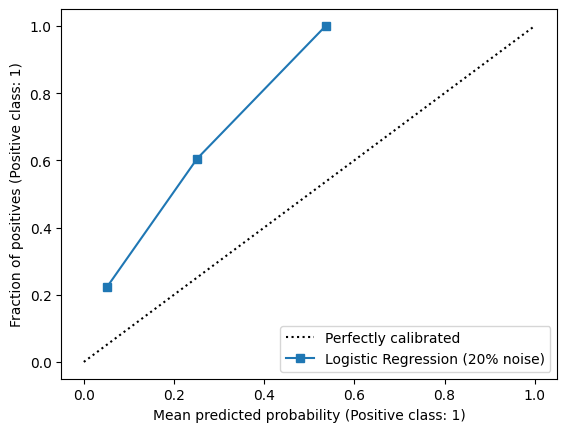

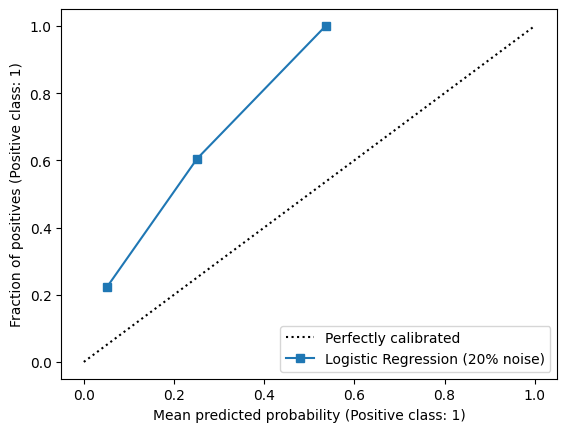

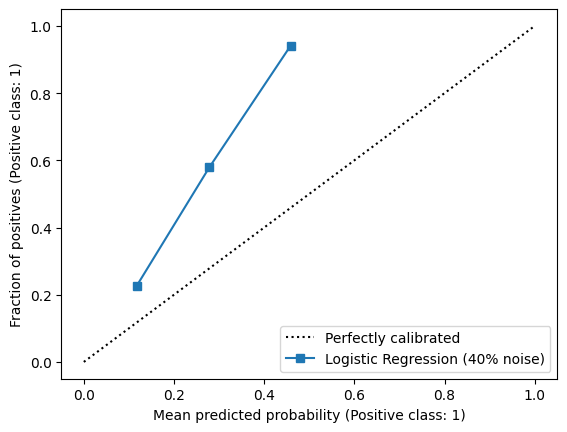

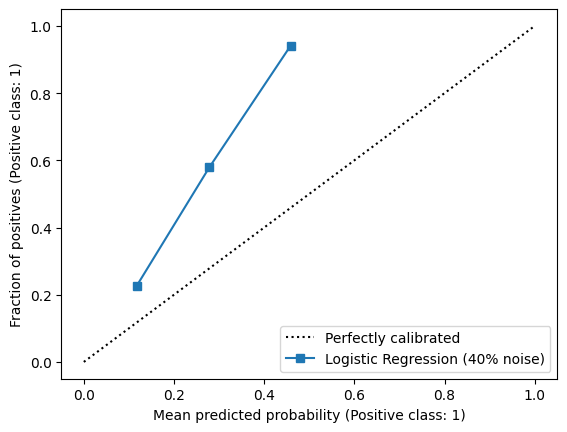

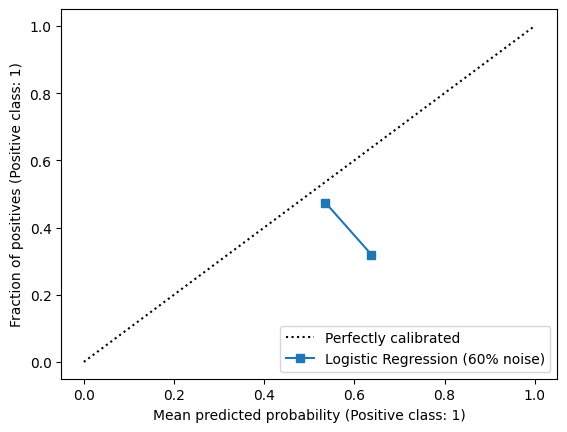

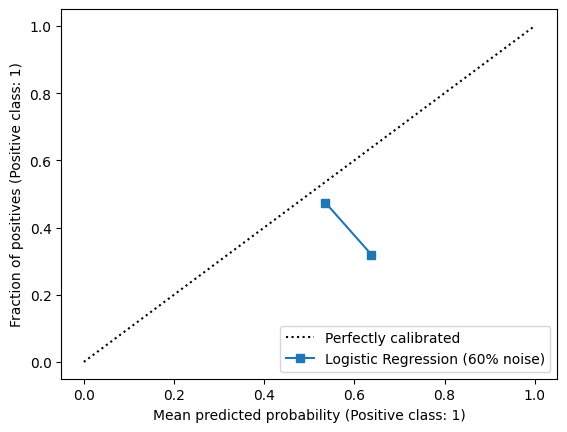

In [30]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

# For the model_lr (the clean model)
y_pred_proba_lr = model_lr.predict_proba(X_test)[:, 1]
display_lr = CalibrationDisplay.from_predictions(y_test, y_pred_proba_lr, name="Logistic Regression")
display_lr.plot()

# For the model_lr_noise_20
y_pred_proba_lr_noise_20 = model_lr_noise_20.predict_proba(X_test)[:, 1]
display_lr_noise_20 = CalibrationDisplay.from_predictions(y_test, y_pred_proba_lr_noise_20, name="Logistic Regression (20% noise)")
display_lr_noise_20.plot()

# For the model_lr_noise_40
y_pred_proba_lr_noise_40 = model_lr_noise_40.predict_proba(X_test)[:, 1]
display_lr_noise_40 = CalibrationDisplay.from_predictions(y_test, y_pred_proba_lr_noise_40, name="Logistic Regression (40% noise)")
display_lr_noise_40.plot()

# For the model_lr_noise_60
y_pred_proba_lr_noise_60 = model_lr_noise_60.predict_proba(X_test)[:, 1]
display_lr_noise_60 = CalibrationDisplay.from_predictions(y_test, y_pred_proba_lr_noise_60, name="Logistic Regression (60% noise)")
display_lr_noise_60.plot()

# Show all the plots together
import matplotlib.pyplot as plt
plt.show()

